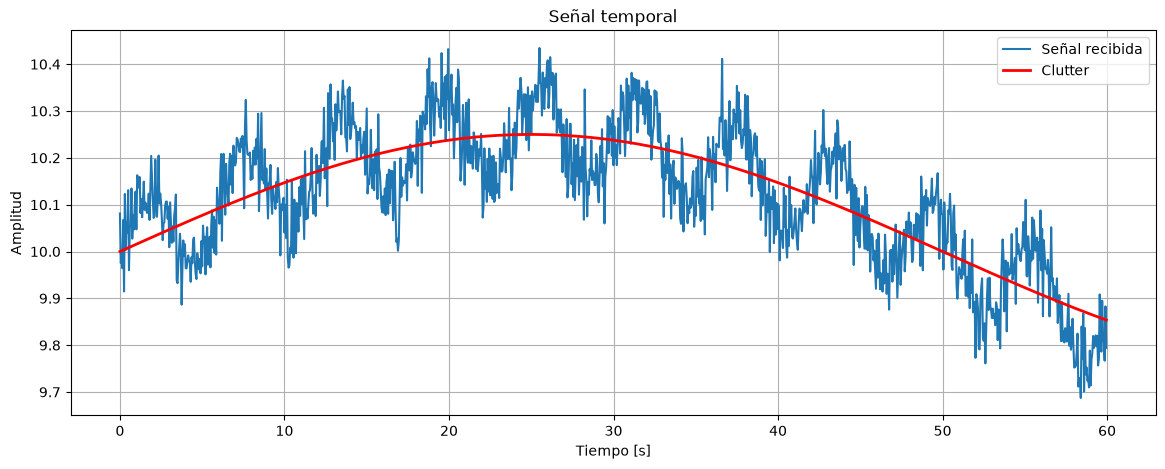

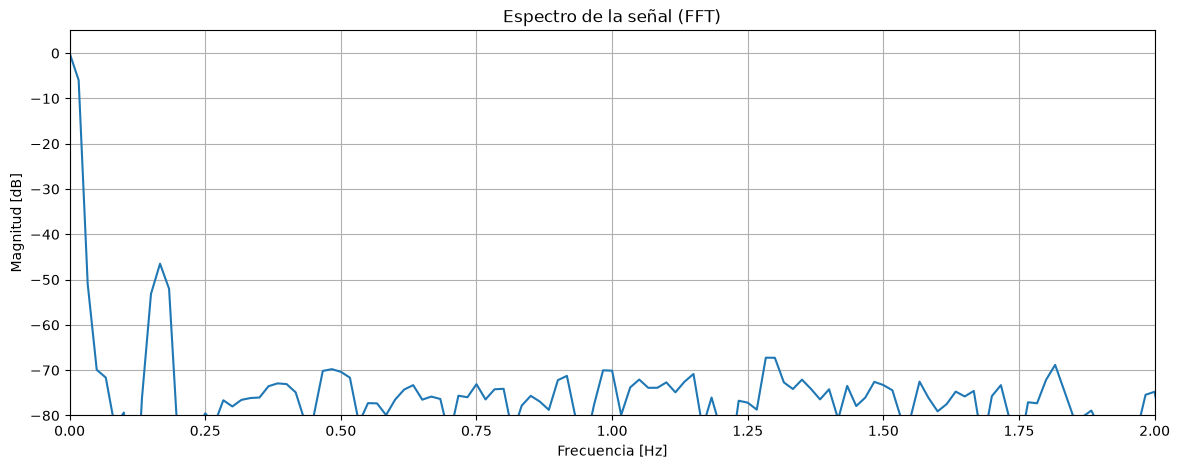

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# Parámetros
# =====================================================

fs = 20                     # Frecuencia de muestreo [Hz]
T = 60                      # Duración de la adquisición [s]

N = int(fs*T)

t = np.arange(N)/fs

# =====================================================
# Respiración
# =====================================================

bpm = 10
f_resp = bpm/60             # Hz

resp = 0.1*np.sin(2*np.pi*f_resp*t)

# =====================================================
# Clutter (eco estático)
# =====================================================

dc = 10.0

# deriva lenta del entorno (muy baja frecuencia)

drift = 0.25*np.sin(2*np.pi*0.01*t)

clutter = dc + drift

# =====================================================
# Ruido
# =====================================================

np.random.seed(1)

noise = 0.05*np.random.randn(N)

# =====================================================
# Señal recibida por el radar
# =====================================================

signal = clutter + resp + noise


# =====================================================
# FFT
# =====================================================

window = np.hanning(N)

signal_fft = np.fft.rfft(signal*window)

freq = np.fft.rfftfreq(N,1/fs)

mag = np.abs(signal_fft)

mag = mag/np.max(mag)

# =====================================================
# Gráficos
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(t,signal,label='Señal recibida')

plt.plot(t,clutter,'r',linewidth=2,label='Clutter')

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.title("Señal temporal")
plt.grid(True)
plt.legend()

plt.show()


plt.figure(figsize=(14,5))

plt.plot(freq,20*np.log10(mag+1e-12))

plt.xlim(0,2)

plt.ylim(-80,5)

plt.grid(True)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud [dB]")

plt.title("Espectro de la señal (FFT)")

plt.show()

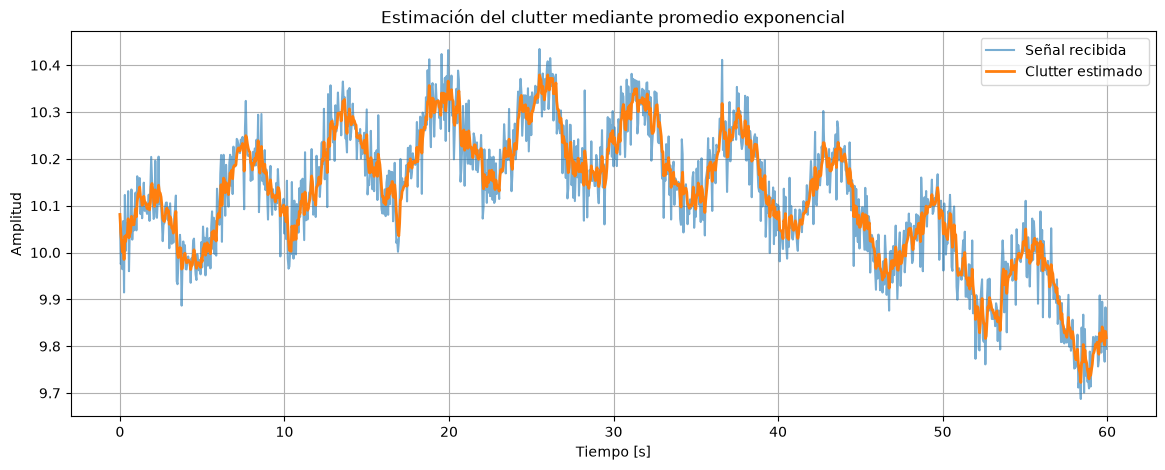

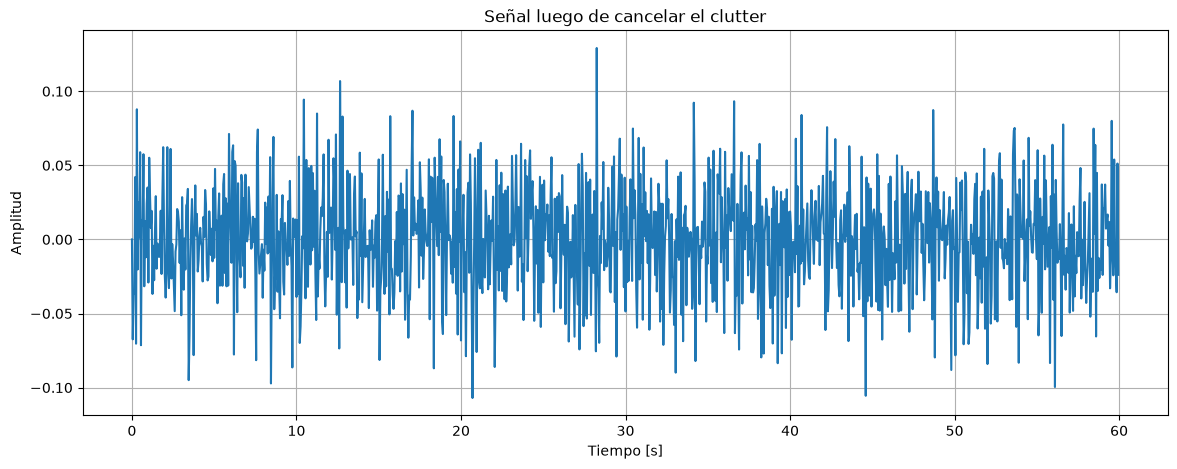

In [9]:
# =====================================================
# Cancelación de clutter mediante promedio exponencial
# =====================================================

alpha = 0.63744          # Factor de olvido

background = np.zeros_like(signal)

background[0] = signal[0]

for n in range(1, len(signal)):
    background[n] = alpha * background[n-1] + (1-alpha) * signal[n]

# Señal sin clutter

signal_clutter = signal - background

# =====================================================
# Graficos
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(t, signal, label="Señal recibida", alpha=0.6)
plt.plot(t, background, linewidth=2, label="Clutter estimado")

plt.grid(True)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")

plt.title("Estimación del clutter mediante promedio exponencial")

plt.legend()

plt.show()

plt.figure(figsize=(14,5))

plt.plot(t, signal_clutter)

plt.grid(True)

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")

plt.title("Señal luego de cancelar el clutter")

plt.show()

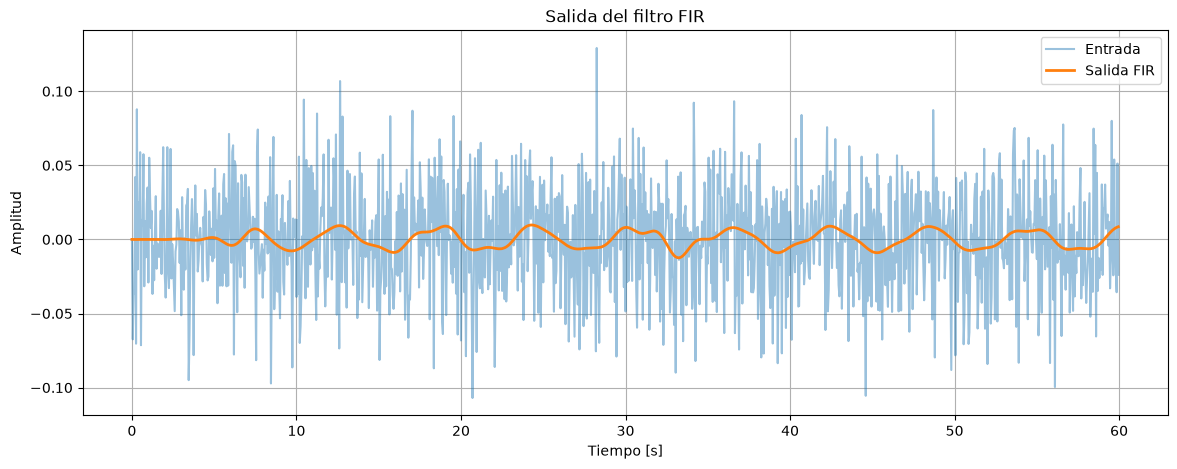

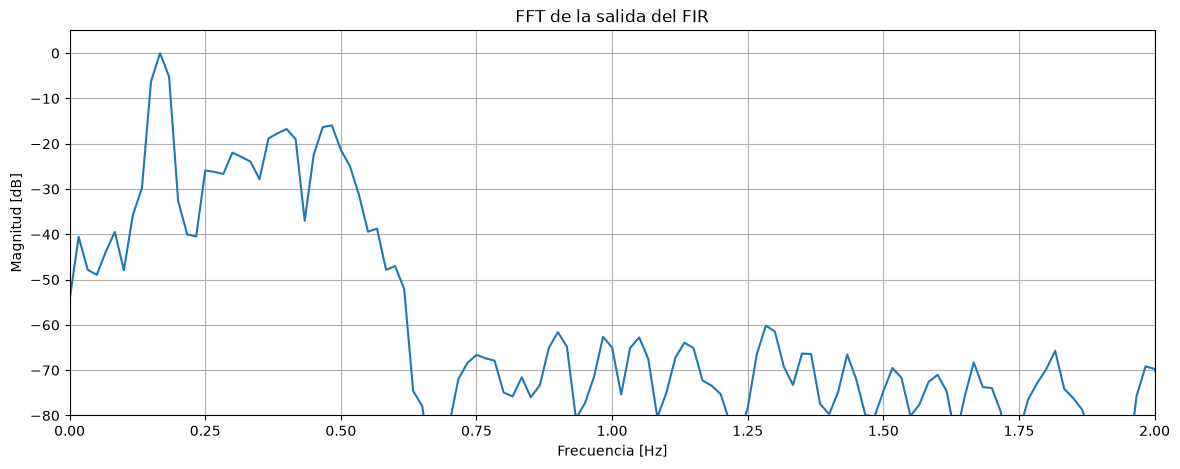

In [10]:
from scipy.signal import lfilter, firwin

# =====================================================
# Coeficientes del FIR
# =====================================================



h = firwin(
    256,
    [0.1,0.5],
    pass_zero='bandpass',
    fs=fs
)

# =====================================================
# Filtrado FIR
# =====================================================

filtered = lfilter(h, 1, signal_clutter)

# =====================================================
# FFT de la salida
# =====================================================

window = np.hanning(len(filtered))

FFT = np.fft.rfft(filtered * window)

freq = np.fft.rfftfreq(len(filtered), 1/fs)

mag = np.abs(FFT)

mag /= np.max(mag)

# =====================================================
# Señal temporal
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(t, signal_clutter, alpha=0.45, label="Entrada")

plt.plot(t, filtered, linewidth=2, label="Salida FIR")

plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")

plt.title("Salida del filtro FIR")

plt.grid(True)

plt.legend()

plt.show()

# =====================================================
# FFT
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(freq,20*np.log10(mag+1e-12))

plt.xlim(0,2)

plt.ylim(-80,5)

plt.grid(True)

plt.xlabel("Frecuencia [Hz]")

plt.ylabel("Magnitud [dB]")

plt.title("FFT de la salida del FIR")

plt.show()

Error máximo: 1.447554e-15


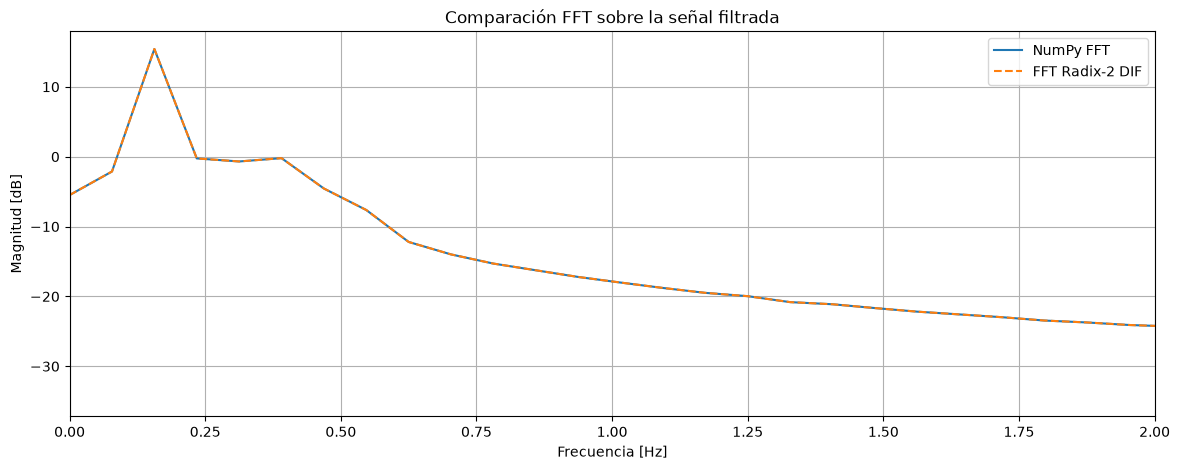

In [4]:
# =====================================================
# FFT referencia sobre la señal filtrada
# =====================================================

N = 256                     # Debe ser potencia de 2

# Tomar las primeras N muestras de la señal filtrada
inicio = (len(filtered)-N)//2
x = filtered[inicio:inicio+N]

# x = filtered[:N]

# FFT de referencia (NumPy)
X_ref = np.fft.fft(x)

# =====================================================
# Funciones auxiliares
# =====================================================

def bit_reverse(x):

    N = len(x)
    bits = int(np.log2(N))

    out = np.zeros(N, dtype=complex)

    for i in range(N):

        b = format(i, '0{}b'.format(bits))
        j = int(b[::-1], 2)

        out[j] = x[i]

    return out


def fft_dif(x):

    x = np.array(x, dtype=complex)

    N = len(x)

    m = N

    while m >= 2:

        half = m // 2

        W = np.exp(-2j * np.pi * np.arange(half) / m)

        for k in range(0, N, m):

            for j in range(half):

                a = x[k + j]
                b = x[k + j + half]

                x[k + j] = a + b
                x[k + j + half] = (a - b) * W[j]

        m //= 2

    return bit_reverse(x)

# =====================================================
# Ejecutar FFT
# =====================================================

X = fft_dif(x)

# =====================================================
# Error
# =====================================================

error = np.max(np.abs(X - X_ref))

print(f"Error máximo: {error:e}")

# =====================================================
# Eje de frecuencias
# =====================================================

freq = np.arange(N) * fs / N

# =====================================================
# Gráfica
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(freq[:N//2],
         20*np.log10(np.abs(X_ref[:N//2]) + 1e-12),
         label='NumPy FFT')

plt.plot(freq[:N//2],
         20*np.log10(np.abs(X[:N//2]) + 1e-12),
         '--',
         label='FFT Radix-2 DIF')

plt.xlim(0,2)

plt.grid(True)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Magnitud [dB]')
plt.title('Comparación FFT sobre la señal filtrada')

plt.legend()

plt.show()

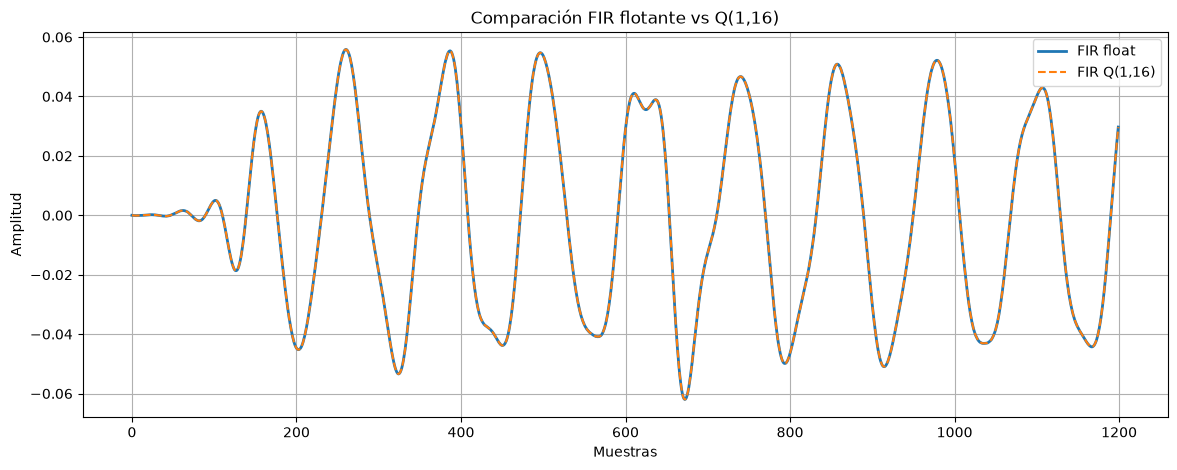

In [5]:
from tool._fixedInt import *

#Para generar el archivo de simulacion

# =====================================================
# Parámetros Q(1,16)
# =====================================================

INT_BITS = 18
FRAC_BITS = 16

# =====================================================
# Coeficientes FIR cuantizados
# =====================================================

coeff = arrayFixedInt(INT_BITS, FRAC_BITS, h)

# =====================================================
# Registro de desplazamiento
# =====================================================

taps = len(h)

delay_line = [0.0]*taps

xn = arrayFixedInt(INT_BITS, FRAC_BITS, delay_line)

signal_xn = [c.value for c in xn]

with open("signal.mem","w") as f:

    for c in signal_xn:

        if c < 0:
            c = (1<<18) + c      # complemento a dos

        f.write(f"{c:05X}\n")

# =====================================================
# Función FIR
# =====================================================

def fir_filter(x,c):

    products = x*c

    acc = products[0]

    for i in range(1,len(products)):
        acc = acc + products[i]

    return acc

# =====================================================
# Filtrado
# =====================================================

filtered_fixed = []

# La entrada será la salida del cancelador de clutter
for sample in signal_clutter:

    delay_line.insert(0,sample)
    delay_line.pop()

    for i in range(taps):
        xn[i].value = delay_line[i]

    y = fir_filter(xn,coeff)

    filtered_fixed.append(y.fValue)

filtered_fixed = np.array(filtered_fixed)

# =====================================================
# Comparación
# =====================================================

plt.figure(figsize=(14,5))

plt.plot(filtered,label="FIR float",linewidth=2)

plt.plot(filtered_fixed,'--',label="FIR Q(1,16)")

plt.grid(True)

plt.legend()

plt.xlabel("Muestras")

plt.ylabel("Amplitud")

plt.title("Comparación FIR flotante vs Q(1,16)")

plt.show()

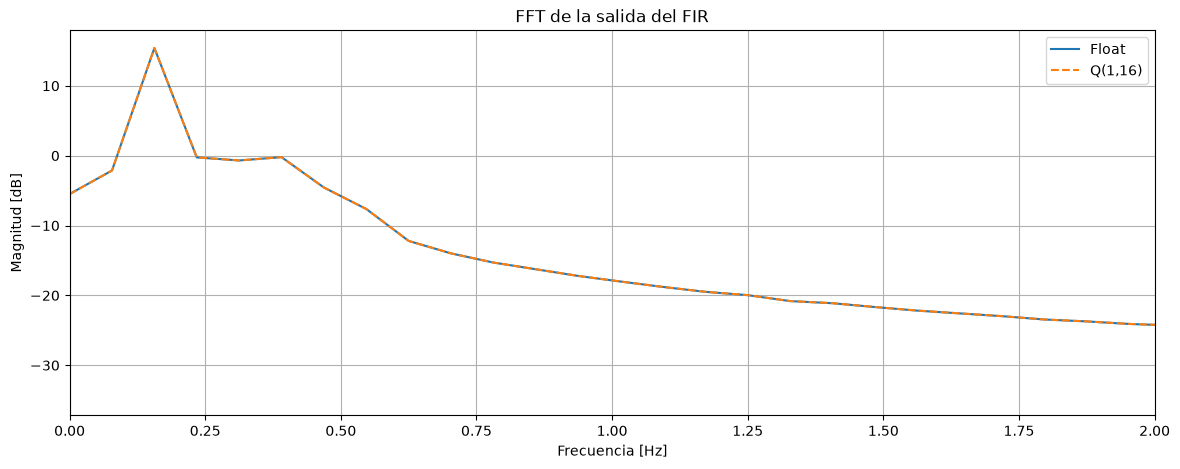

In [6]:
N = 256

inicio = (len(filtered)-N)//2

x_float = filtered[inicio:inicio+N]

x_fixed = filtered_fixed[inicio:inicio+N]

FFT_float = np.fft.fft(x_float)

FFT_fixed = np.fft.fft(x_fixed)

freq = np.arange(N)*fs/N

plt.figure(figsize=(14,5))

plt.plot(freq[:N//2],
         20*np.log10(np.abs(FFT_float[:N//2])+1e-12),
         label="Float")

plt.plot(freq[:N//2],
         20*np.log10(np.abs(FFT_fixed[:N//2])+1e-12),
         '--',
         label="Q(1,16)")

plt.xlim(0,2)

plt.grid(True)

plt.legend()

plt.xlabel("Frecuencia [Hz]")

plt.ylabel("Magnitud [dB]")

plt.title("FFT de la salida del FIR")

plt.show()

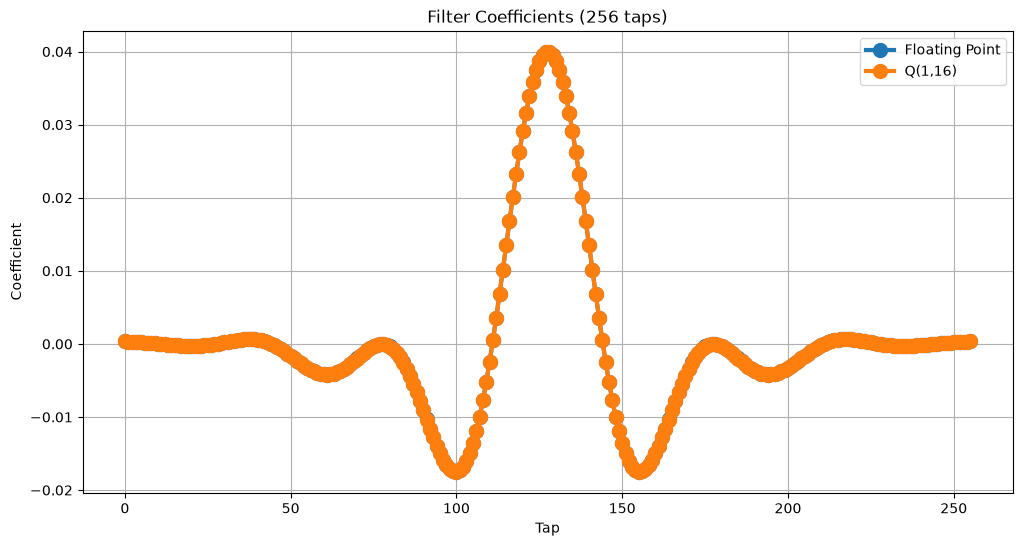

Error máximo : 1.5194833048817052e-05
Error medio  : 7.362820502223705e-06
Error RMS    : 8.615002691819688e-06


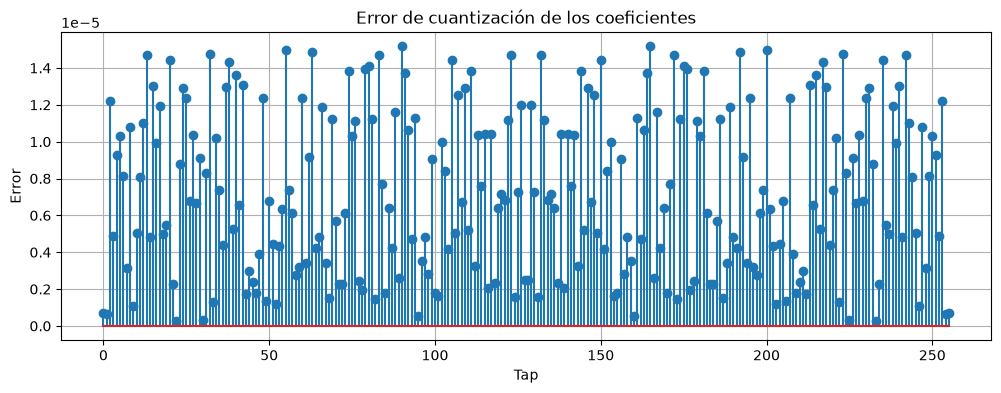

In [7]:
coeff_fixed = np.array([c.fValue for c in coeff])

import numpy as np
import matplotlib.pyplot as plt

# ============================================
# Coeficientes originales
# ============================================

coeff_float = np.array(h)

# ============================================
# Coeficientes cuantizados
# ============================================

coeff_fixed = np.array([c.fValue for c in coeff])


# ============================================
# Gráfico
# ============================================

plt.figure(figsize=(12,6))

plt.plot(coeff_float,
         '-o',
         linewidth=3,
         markersize=10,
         label='Floating Point')

plt.plot(coeff_fixed,
         '-o',
         linewidth=3,
         markersize=10,
         label='Q(1,16)')

plt.grid(True)

plt.title(f'Filter Coefficients ({len(coeff_float)} taps)')

plt.xlabel('Tap')

plt.ylabel('Coefficient')

plt.legend()

plt.show()

error = coeff_float - coeff_fixed

print("Error máximo :", np.max(np.abs(error)))
print("Error medio  :", np.mean(np.abs(error)))
print("Error RMS    :", np.sqrt(np.mean(error**2)))

plt.figure(figsize=(12,4))

plt.stem(error)

plt.grid(True)

plt.xlabel("Tap")

plt.ylabel("Error")

plt.title("Error de cuantización de los coeficientes")

plt.show()

In [8]:
mag = np.abs(FFT_fixed)

k_min = int(np.ceil(0.1*N/fs))
k_max = int(np.floor(0.5*N/fs))

print(f'{k_min}')
print(f'{k_max}')


k_peak = np.argmax(mag[k_min:k_max+1]) + k_min

print(f'{k_peak}')

f_resp = k_peak*fs/N

bpm = 60*f_resp

print("Frecuencia:",f_resp,"Hz")
print("Respiración:",bpm,"BPM")

2
6
2
Frecuencia: 0.15625 Hz
Respiración: 9.375 BPM
